In [41]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt

In [42]:
# Carregar o arquivo 
df_colesterol = pd.read_csv('./datasets/dataset_colesterol.csv')

In [43]:
# Checar a estrutura 
df_colesterol.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Id                  1000 non-null   int64  
 1   Grupo Sanguíneo     996 non-null    str    
 2   Fumante             997 non-null    str    
 3   Nível de Atividade  996 non-null    str    
 4   Idade               997 non-null    float64
 5   Peso                997 non-null    float64
 6   Altura              997 non-null    float64
 7   Colesterol          1000 non-null   float64
dtypes: float64(4), int64(1), str(3)
memory usage: 73.2 KB


In [44]:
# Remover coluna Id
df_colesterol.drop(columns=['Id'], inplace=True)

In [45]:
# Renomear as colunas usando métodos de string do python como str.lower() e str.replace()
df_colesterol.columns = df_colesterol.columns.str.lower()
df_colesterol.columns = df_colesterol.columns.str.replace(' ', '_')
df_colesterol.columns

Index(['grupo_sanguíneo', 'fumante', 'nível_de_atividade', 'idade', 'peso',
       'altura', 'colesterol'],
      dtype='str')

In [46]:
# Usando outro método para renomear colunas de um forma mais direta
df_colesterol.columns = [
    'grupo_sanguineo',
    'fumante',
    'nivel_atividade_fisica',
    'idade',
    'peso',
    'altura',
    'nivel_colesterol'
]
df_colesterol.columns

Index(['grupo_sanguineo', 'fumante', 'nivel_atividade_fisica', 'idade', 'peso',
       'altura', 'nivel_colesterol'],
      dtype='str')

In [47]:
# Copiar df para df eda
df_colesterol_eda = df_colesterol.copy()

In [48]:
# Copiar df para df Bucketing
df_colesterol_bucketing = df_colesterol.copy()

### EDA

In [49]:
# Visualizar os dados
df_colesterol_eda.head(10)

,grupo_sanguineo,fumante,nivel_atividade_fisica,idade,peso,altura,nivel_colesterol
0,B,Sim,Baixo,33.0,85.1,186.0,199.63
1,A,Não,Moderado,68.0,105.0,184.0,236.98
2,O,Não,Alto,25.0,64.8,180.0,161.79
3,A,Não,Alto,43.0,120.2,167.0,336.24
4,AB,Não,Baixo,79.0,88.5,175.0,226.23
5,B,Não,Baixo,68.0,66.8,170.0,185.31
6,A,Sim,Baixo,60.0,117.3,181.0,289.33
7,O,Sim,Moderado,35.0,86.9,174.0,216.48
8,O,Não,Baixo,62.0,81.3,166.0,235.30
9,B,Sim,Alto,44.0,32.7,165.0,97.79


In [50]:
df_colesterol_eda['nivel_atividade_fisica'].unique()

<ArrowStringArray>
['Baixo', 'Moderado', 'Alto', nan]
Length: 4, dtype: str

In [51]:
# Detectar valores ausentes 
df_colesterol_eda.isna().sum()

grupo_sanguineo           4
fumante                   3
nivel_atividade_fisica    4
idade                     3
peso                      3
altura                    3
nivel_colesterol          0
dtype: int64

In [52]:
# Medidas estatísticas do df
df_colesterol_eda.describe()

,idade,peso,altura,nivel_colesterol
count,997.000000,997.000000,997.000000,1000.000000
mean,49.206620,76.496690,174.889669,199.453260
std,17.476704,21.439132,8.844703,50.625152
min,20.000000,15.400000,160.000000,36.260000
25%,34.000000,61.700000,167.000000,166.345000
50%,49.000000,75.500000,175.000000,199.455000
75%,65.000000,90.200000,183.000000,233.785000
max,79.000000,158.100000,190.000000,372.670000


### Imputação de valores ausentes
- **Numéricas (idade, peso, altura):** mediana, por ser robusta a outliers
  (ex.: peso mínimo de 15,4 kg, provável erro de registro). Neste dataset,
  média e mediana são próximas (peso: 76,5 vs 75,5), então o impacto é pequeno.
- **Categóricas (grupo sanguíneo, fumante, atividade):** moda, o valor mais frequente.
- Poucos nulos (3–4 por coluna, <0,5% dos dados), por isso imputar em vez de descartar linhas.


In [53]:
# Coletar médidas das variaveis categoricas
moda_grupo_sangue = df_colesterol_eda['grupo_sanguineo'].mode()[0]
moda_fumante = df_colesterol_eda['fumante'].mode()[0]
moda_nivel_atividade = df_colesterol_eda['nivel_atividade_fisica'].mode()[0]

In [54]:
# Coletar médidas das variaveis numericas
mediana_idade = df_colesterol_eda['idade'].median()
mediana_peso = df_colesterol_eda['peso'].median()
mediana_altura = df_colesterol_eda['altura'].median()


In [55]:
# Imputar valores ausentes 
df_colesterol_eda.fillna(value={'grupo_sanguineo' :moda_grupo_sangue,
                                'fumante': moda_fumante,
                                'nivel_atividade_fisica': moda_nivel_atividade,
                                'idade': mediana_idade,
                                'peso': mediana_peso,
                                'altura': mediana_altura}, inplace=True);

In [58]:
# Checando os dados nulos novamente 
df_colesterol_eda.isna().sum()

grupo_sanguineo           0
fumante                   0
nivel_atividade_fisica    0
idade                     0
peso                      0
altura                    0
nivel_colesterol          0
dtype: int64

In [59]:
# Converter idade e altura em inteiro 
df_colesterol_eda['idade'] = df_colesterol_eda['idade'].astype(int)

In [60]:
df_colesterol_eda['altura'] = df_colesterol_eda['altura'].astype(int)

In [61]:
# Estrutura do df
df_colesterol_eda.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   grupo_sanguineo         1000 non-null   str    
 1   fumante                 1000 non-null   str    
 2   nivel_atividade_fisica  1000 non-null   str    
 3   idade                   1000 non-null   int64  
 4   peso                    1000 non-null   float64
 5   altura                  1000 non-null   int64  
 6   nivel_colesterol        1000 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 65.1 KB


In [63]:
# Visualizar os dados
df_colesterol_eda.head(10)

,grupo_sanguineo,fumante,nivel_atividade_fisica,idade,peso,altura,nivel_colesterol
0,B,Sim,Baixo,33,85.1,186,199.63
1,A,Não,Moderado,68,105.0,184,236.98
2,O,Não,Alto,25,64.8,180,161.79
3,A,Não,Alto,43,120.2,167,336.24
4,AB,Não,Baixo,79,88.5,175,226.23
5,B,Não,Baixo,68,66.8,170,185.31
6,A,Sim,Baixo,60,117.3,181,289.33
7,O,Sim,Moderado,35,86.9,174,216.48
8,O,Não,Baixo,62,81.3,166,235.30
9,B,Sim,Alto,44,32.7,165,97.79


### Verificar / detectar outliers

<Axes: xlabel='peso'>

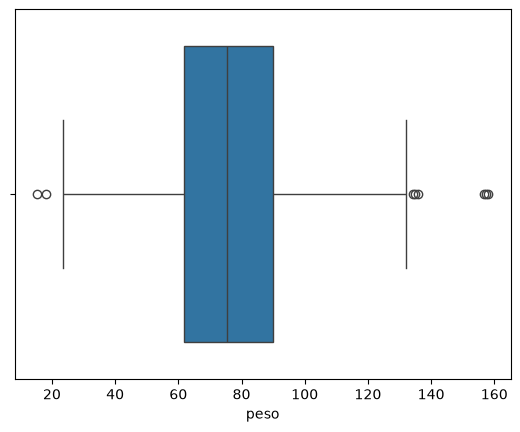

In [66]:
# Verificando a variável peso
sns.boxplot(data=df_colesterol_eda, x='peso')

In [69]:
# Filtrar o publico a ser removido 
df_colesterol_eda[df_colesterol_eda['peso'] < 40].peso.count()

np.int64(37)

In [71]:
# Remover publico do dataframe
df_colesterol_eda.drop(df_colesterol_eda[df_colesterol_eda['peso'] < 40].index, axis=0, inplace=True)

In [72]:
# Checando o df
df_colesterol_eda.info()

<class 'pandas.DataFrame'>
Index: 963 entries, 0 to 999
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   grupo_sanguineo         963 non-null    str    
 1   fumante                 963 non-null    str    
 2   nivel_atividade_fisica  963 non-null    str    
 3   idade                   963 non-null    int64  
 4   peso                    963 non-null    float64
 5   altura                  963 non-null    int64  
 6   nivel_colesterol        963 non-null    float64
dtypes: float64(2), int64(2), str(3)
memory usage: 70.4 KB


<Axes: xlabel='peso'>

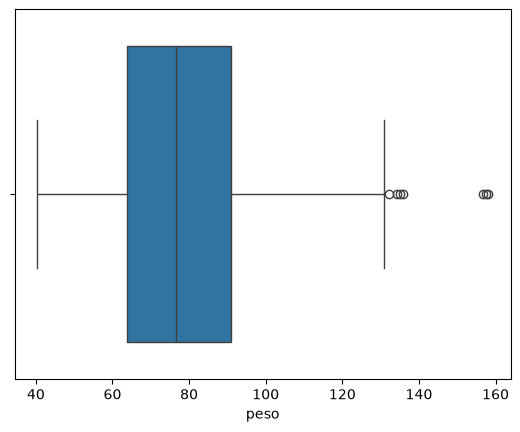

In [73]:
# Checando no boxplot novamente 
sns.boxplot(data=df_colesterol_eda, x='peso')

<Axes: xlabel='altura'>

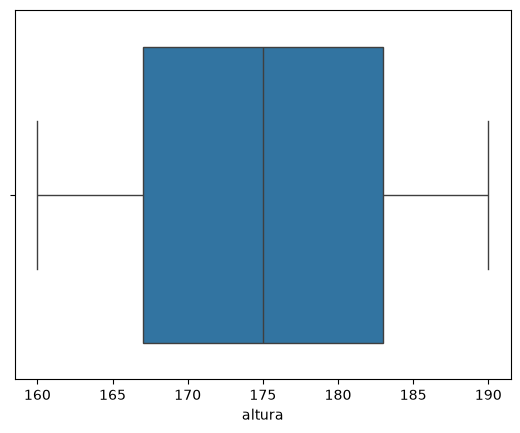

In [75]:
# Verificando a variável altura
sns.boxplot(data=df_colesterol_eda, x='altura')

<Axes: xlabel='nivel_colesterol'>

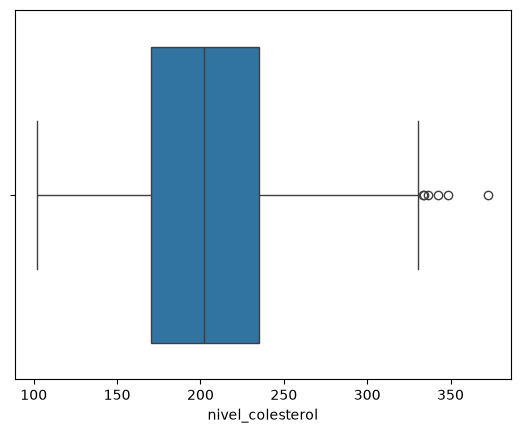

In [76]:
# Verificando a variável nivel colesterol
sns.boxplot(data=df_colesterol_eda, x='nivel_colesterol')

### Tratamento de outliers
- **Peso:** removidos 37 registros com peso < 40 kg (3,7% da base). Todos são adultos
  com altura entre 160 e 190 cm, o que resulta em IMC entre 4,7 e 15,4, valores
  fisiologicamente implausíveis e provavelmente erros de registro. O critério do IQR
  (limite inferior de 19 kg) só detectaria 2 deles; por isso o corte foi definido
  por conhecimento de domínio.
- **Pesos altos (130–158 kg) e outliers de colesterol:** mantidos, por serem valores
  raros, mas plausíveis e coerentes entre si (pacientes altos e com colesterol elevado).
- Base final da EDA: 963 registros.
